# Experiment 6: Support Vector Machine (SVM)

**Name:** Koushal Gupta  

## Aim
To implement a **Support Vector Machine (SVM)** classifier on the **Iris dataset** and compare **Linear** and **RBF** kernels.

## Concept
SVM finds the best separating boundary (hyperplane) that maximizes the margin between classes. Kernels like `linear` and `rbf` handle both linear and non-linear boundaries.


In [1]:
# Step 1: Import libraries
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [2]:
# Step 2: Load Iris dataset and split into train/test sets
iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature scaling improves SVM performance
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [3]:
# Step 3: Train SVM with Linear kernel and RBF kernel
svm_linear = SVC(kernel="linear", C=1.0, random_state=42)
svm_linear.fit(X_train, y_train)

svm_rbf = SVC(kernel="rbf", C=1.0, random_state=42)
svm_rbf.fit(X_train, y_train)

# Step 4: Compare accuracy
pred_linear = svm_linear.predict(X_test)
pred_rbf = svm_rbf.predict(X_test)

print("Linear SVM Accuracy:", round(accuracy_score(y_test, pred_linear), 4))
print("RBF SVM Accuracy:   ", round(accuracy_score(y_test, pred_rbf), 4))
print("\nClassification Report (RBF SVM):")
print(classification_report(y_test, pred_rbf, target_names=iris.target_names))


Linear SVM Accuracy: 0.9667
RBF SVM Accuracy:    1.0

Classification Report (RBF SVM):
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



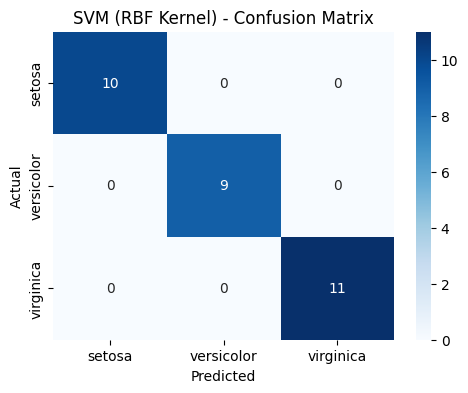

In [4]:
# Step 5: Plot Confusion Matrix for RBF SVM
cm = confusion_matrix(y_test, pred_rbf)
plt.figure(figsize=(5.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title("SVM (RBF Kernel) - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


## Conclusion
- Both **Linear** and **RBF** kernel SVMs classified the Iris test samples with high accuracy.
- Scaling features with `StandardScaler` helps SVM find an optimal margin.
